# Chronic Kidney Disease (UCI dataset)

## 1. Load the dataset

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme()

DATA_FILE = (
    Path("chronic+kidney+disease")
    / "Chronic_Kidney_Disease"
    / "chronic_kidney_disease.csv"
)

df = pd.read_csv(DATA_FILE)

print(f"Loaded {DATA_FILE.resolve()}")
df.head()

Loaded D:\Projects\ML\chronic+kidney+disease\Chronic_Kidney_Disease\chronic_kidney_disease.csv


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


## 2. Quick look

In [ ]:
print(f"Shape     : {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Numeric   : {df.select_dtypes('number').shape[1]} columns")
print(f"Text      : {df.select_dtypes(exclude='number').shape[1]} columns")
print(f"Duplicates: {int(df.duplicated().sum())} rows")
print()
df.info()

Shape     : 400 rows x 25 columns
Numeric   : 14 columns
Text      : 11 columns
Duplicates: 0 rows

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    str    
 6   pc      335 non-null    str    
 7   pcc     396 non-null    str    
 8   ba      396 non-null    str    
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    str    
 19  dm      398 non-null    

In [ ]:
# How many patients have CKD, how many do not
df["class"].value_counts()

class
ckd       250
notckd    150
Name: count, dtype: int64

## 3. Null values BEFORE cleaning

In [ ]:
nulls_before = df.isna().sum()

print(f"Total null values : {int(nulls_before.sum())}")
print(f"Columns with nulls: {int((nulls_before > 0).sum())} of {df.shape[1]}")
print(f"Rows with a null  : {int(df.isna().any(axis=1).sum())}")

nulls_before[nulls_before > 0].sort_values(ascending=False)

Total null values : 1012
Columns with nulls: 24 of 25
Rows with a null  : 242


rbc      152
rbcc     131
wbcc     106
pot       88
sod       87
pcv       71
pc        65
hemo      52
su        49
sg        47
al        46
bgr       44
bu        19
sc        17
bp        12
age        9
pcc        4
ba         4
htn        2
dm         2
cad        2
appet      1
pe         1
ane        1
dtype: int64

## 4. Fill the nulls (simple way)

* **Numeric columns** -> filled with the **median** (middle value, not upset by outliers)
* **Text columns** -> filled with the **most common value** (mode)

Only `1012` of the `10000` cells are missing, so this is enough here.

In [ ]:
df_clean = df.copy()

num_cols = list(df_clean.select_dtypes("number").columns)
cat_cols = list(df_clean.select_dtypes(exclude="number").columns)

df_clean[num_cols] = df_clean[num_cols].fillna(df_clean[num_cols].median())
df_clean[cat_cols] = df_clean[cat_cols].fillna(df_clean[cat_cols].mode().iloc[0])

print(f"Filled {len(num_cols)} numeric columns with the median")
print(f"Filled {len(cat_cols)} text columns with the mode")

Filled 14 numeric columns with the median
Filled 11 text columns with the mode


In [ ]:
nulls_after = int(df_clean.isna().sum().sum())
print(f"Null values BEFORE: {int(nulls_before.sum())}")
print(f"Null values AFTER : {nulls_after}")
assert nulls_after == 0, "still missing values"
print("OK - no missing values left")

Null values BEFORE: 1012
Null values AFTER : 0
OK - no missing values left


## 5. Turn text into numbers

All 11 text columns are yes/no style, so a simple mapping is enough:

| Text | Becomes |
|---|---|
| yes / normal / present / good / ckd | `1` |
| no / abnormal / notpresent / poor / notckd | `0` |

`class` becomes the target: `ckd = 1`, `notckd = 0`.

In [ ]:
binary_map = {
    "yes": 1, "no": 0,
    "normal": 1, "abnormal": 0,
    "present": 1, "notpresent": 0,
    "good": 1, "poor": 0,
    "ckd": 1, "notckd": 0,
}

df_clean = df_clean.replace(binary_map)
df_clean[cat_cols] = df_clean[cat_cols].astype(int)   # keep the columns numeric

df_clean.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,1,0,0,1
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.8,0,0,0,1,0,0,1
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.8,0,1,0,0,0,1,1
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,0,0,0,1,1,1
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,0,0,1,0,0,1


## 6. Plots

**6.1 How balanced is the target?**

250 CKD vs 150 healthy: not perfectly balanced, but close enough to train on.

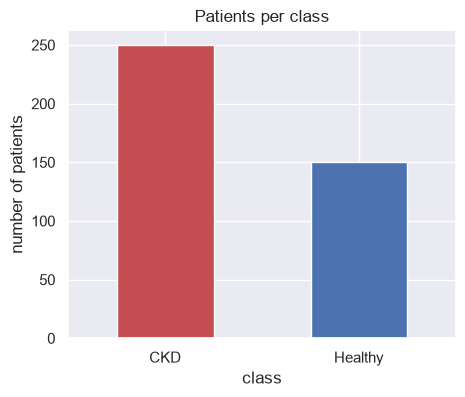

In [ ]:
counts = df_clean["class"].value_counts().rename(index={1: "CKD", 0: "Healthy"})

counts.plot(kind="bar", color=["#c44e52", "#4c72b0"], rot=0, figsize=(5, 4))
plt.title("Patients per class")
plt.ylabel("number of patients")
plt.show()

**6.2 Distribution of every measurement**

Histograms show the spread of each numeric column. Long tails (e.g. `sc`, `bgr`) are where the outliers live.

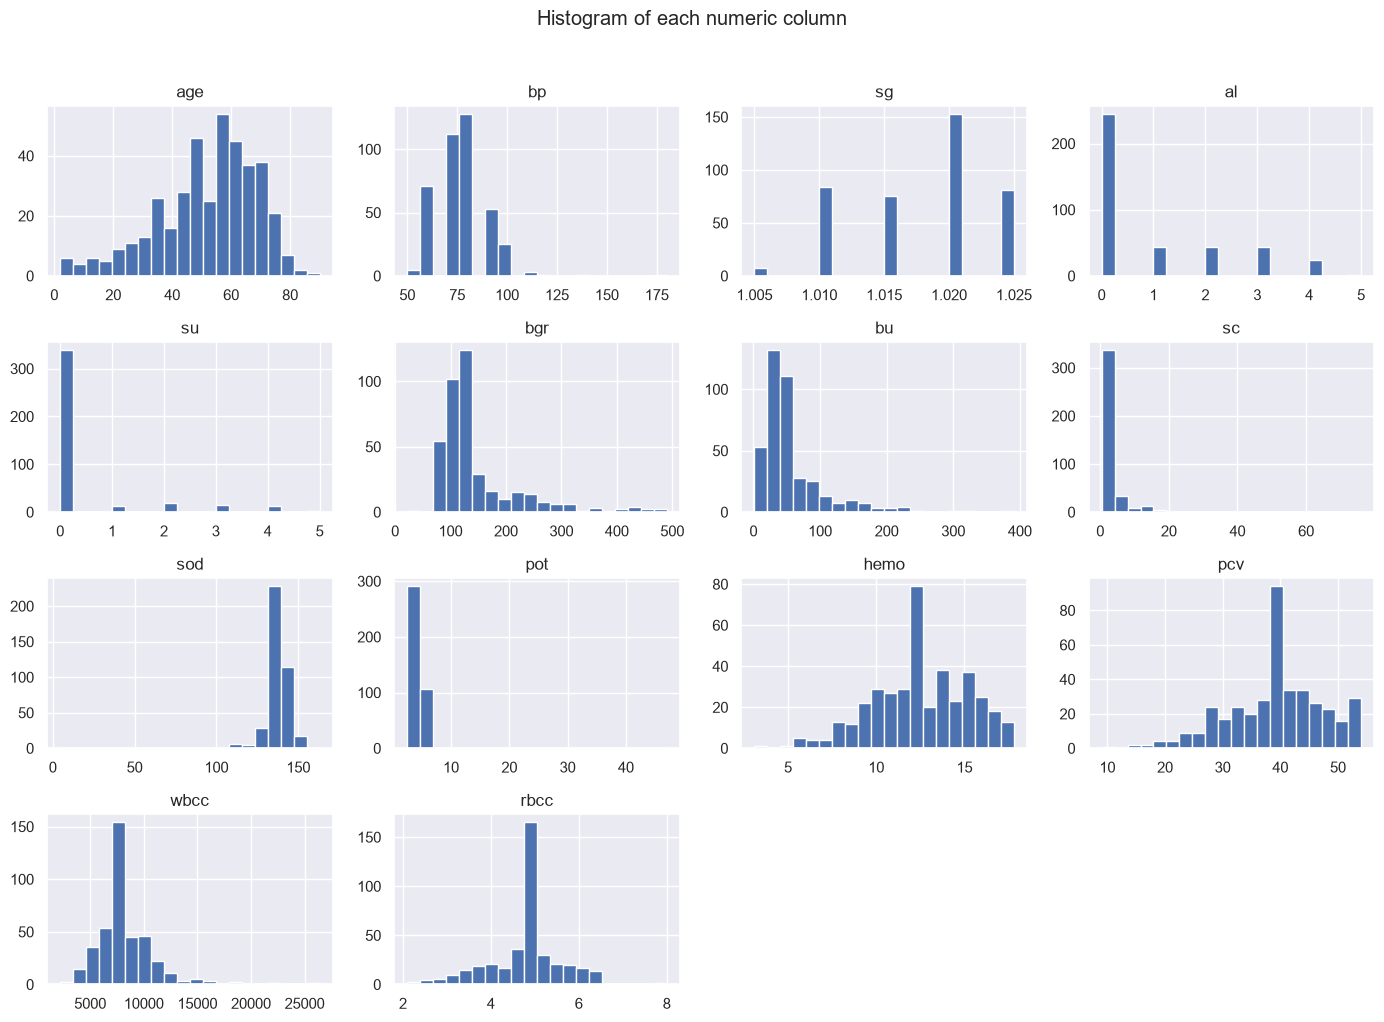

In [ ]:
df_clean[num_cols].hist(figsize=(14, 10), bins=20, color="#4c72b0", edgecolor="white")
plt.suptitle("Histogram of each numeric column", y=1.02)
plt.tight_layout()
plt.show()

**6.3 Correlation heatmap**

Red = the two columns move together, blue = they move in opposite directions. Strong blocks
mean the columns carry the same information (here `pcv`/`hemo`, `rbcc`/`pcv`).

The `class` row shows which measurements separate the two groups: `hemo` (-0.73), `pcv` (-0.67),
`sg` (-0.66), `htn` (+0.59), `rbcc` (-0.57). Negative = the value drops when the patient has CKD
(low hemoglobin / packed cell volume is typical), positive = it rises.

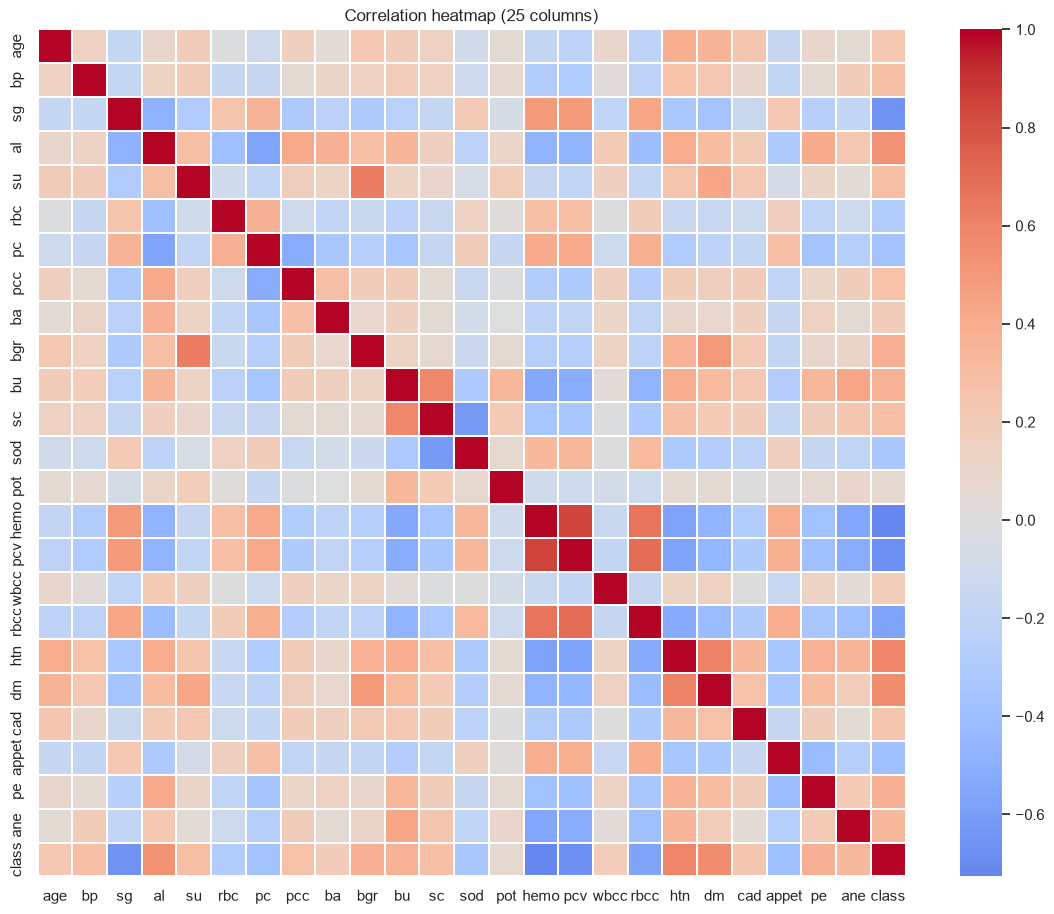

In [ ]:
plt.figure(figsize=(14, 11))
sns.heatmap(df_clean.corr(), cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Correlation heatmap (25 columns)")
plt.show()

## 7. Outlier detection and removal

Simple **IQR rule**: for each measurement, anything below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR` is an outlier. In medical data a single odd value is often a real sick patient, so instead of deleting every flagged row (that would throw away 48% of the data!) we delete only patients flagged in **3 or more columns** - those are the truly extreme records.

In [ ]:
# fences for every numeric column
fence_low, fence_high = {}, {}

for col in num_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    fence_low[col] = q1 - 1.5 * iqr
    fence_high[col] = q3 + 1.5 * iqr

# how many outliers per column
outliers_per_column = {
    col: int(((df_clean[col] < fence_low[col]) | (df_clean[col] > fence_high[col])).sum())
    for col in num_cols
}
pd.Series(outliers_per_column, name="outliers").sort_values(ascending=False)

rbcc    75
su      61
sc      53
bgr     53
bu      41
bp      36
sod     18
wbcc    17
pot     14
age     10
sg       7
pcv      6
hemo     2
al       0
Name: outliers, dtype: int64

In [ ]:
# how many columns each patient is an outlier in
is_outlier = pd.DataFrame(
    {
        col: (df_clean[col] < fence_low[col]) | (df_clean[col] > fence_high[col])
        for col in num_cols
    }
)
outlier_columns_per_patient = is_outlier.sum(axis=1)

print("patients flagged in N columns:")
print(outlier_columns_per_patient.value_counts().sort_index().to_string())

patients flagged in N columns:
0    206
1     96
2     47
3     22
4     17
5      6
6      4
7      1
8      1


In [ ]:
remove = outlier_columns_per_patient >= 3

print(f"Rows BEFORE removal: {len(df_clean)}")
print(f"Rows to remove     : {int(remove.sum())} ({remove.mean():.1%})")

df_clean = df_clean[~remove]

print(f"Rows AFTER removal : {len(df_clean)}")
print(f"Class balance      : {df_clean['class'].value_counts().to_dict()}")

Rows BEFORE removal: 400
Rows to remove     : 51 (12.8%)
Rows AFTER removal : 349
Class balance      : {1: 199, 0: 150}


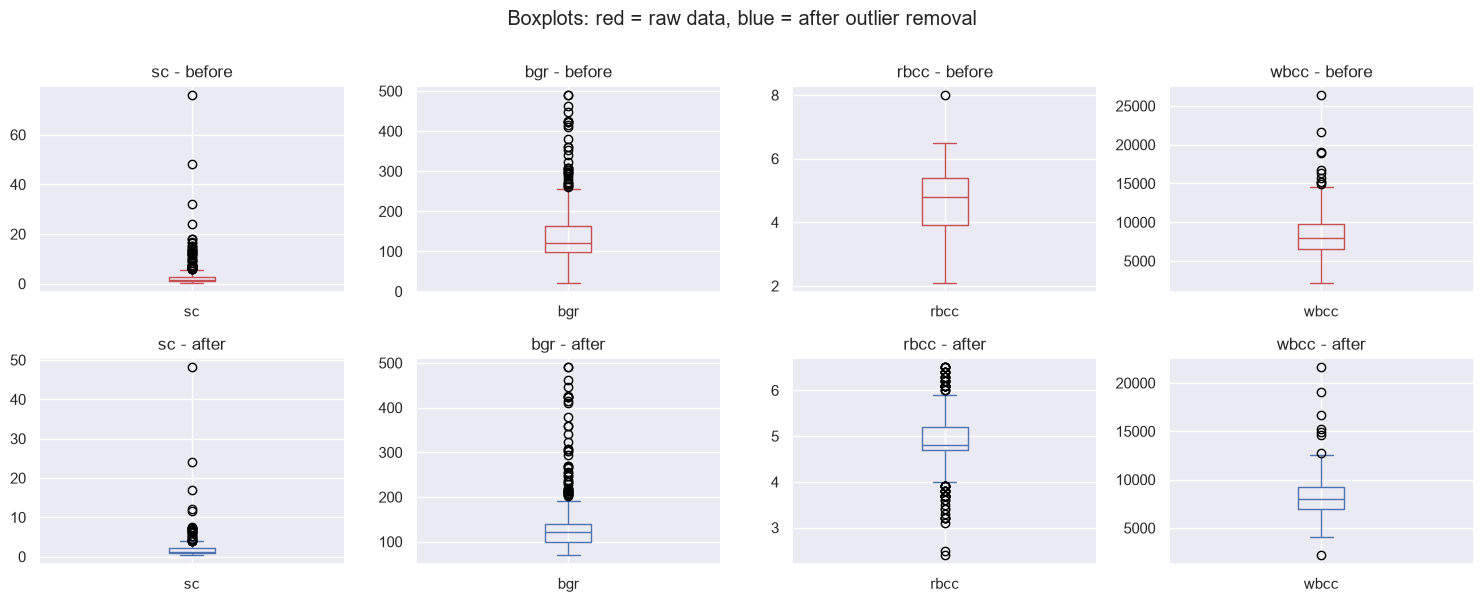

In [ ]:
# before vs after, on the columns with the wildest spread
cols_to_plot = ["sc", "bgr", "rbcc", "wbcc"]

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for i, col in enumerate(cols_to_plot):
    df[col].plot(kind="box", ax=axes[0, i], color="#c44e52")
    df_clean[col].plot(kind="box", ax=axes[1, i], color="#4c72b0")
    axes[0, i].set_title(f"{col} - before")
    axes[1, i].set_title(f"{col} - after")
    axes[0, i].set_xlabel("")
    axes[1, i].set_xlabel("")
plt.suptitle("Boxplots: red = raw data, blue = after outlier removal", y=1.0)
plt.tight_layout()
plt.show()

**7.1 Heatmap again, on the clean data**

The same relationships, now without the extreme records pulling the numbers around.

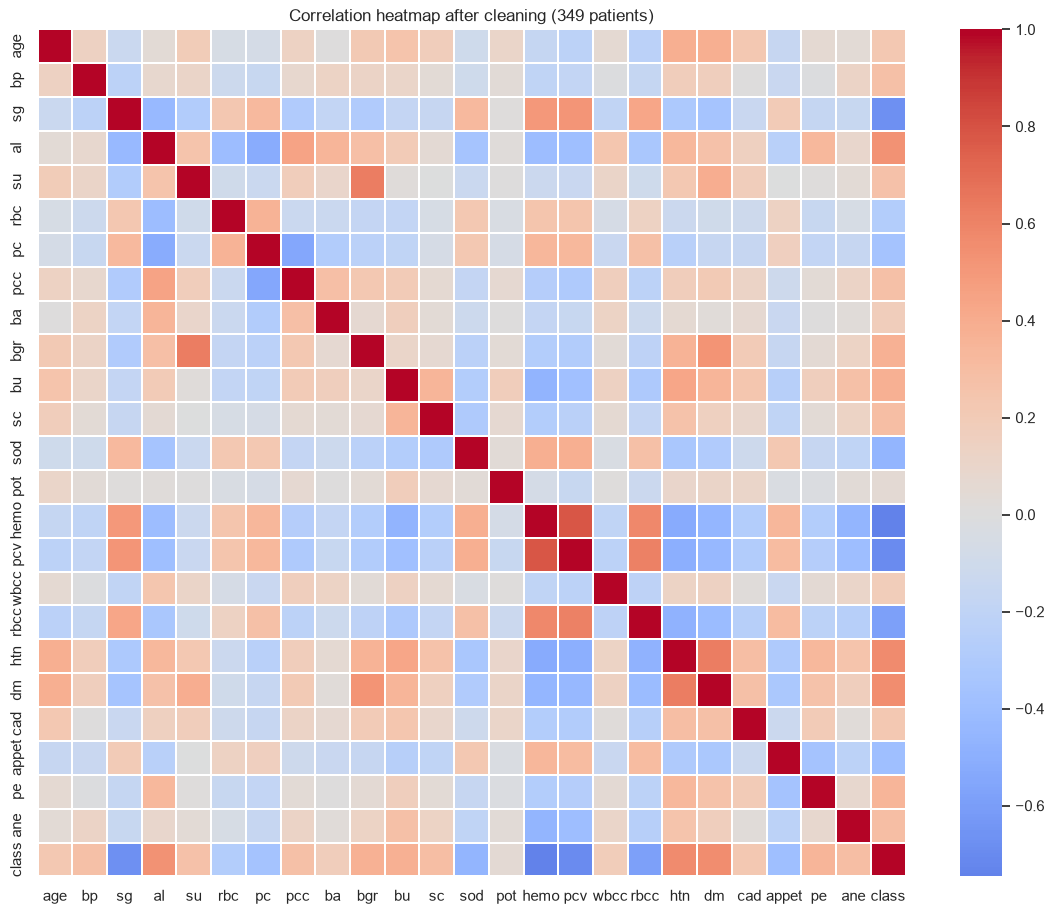

In [ ]:
plt.figure(figsize=(14, 11))
sns.heatmap(df_clean.corr(), cmap="coolwarm", center=0, linewidths=0.3)
plt.title(f"Correlation heatmap after cleaning ({len(df_clean)} patients)")
plt.show()

## 8. Split the data into train / test

* `X` = the 24 input columns (measurements)
* `y` = `class` = what we want to predict (`1` = has CKD, `0` = healthy)
* 80% of patients are used to **train**, 20% are kept aside to **test** the model

In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="class")
y = df_clean["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} patients")
print(f"Test : {X_test.shape[0]} patients")

Train: 279 patients
Test : 70 patients


## 9. Train a simple logistic regression

Logistic regression learns a formula from the 24 columns and outputs the probability that a patient has CKD. Probability above 0.5 -> predicted `CKD`.

The values are put on the same 0-1 scale first (min-max scaling), otherwise the columns with big numbers (`wbcc` ~ 10000) would drown out the small ones (`sg` ~ 1.02). **The same min/max is used for train and test** so the test set stays fair.

In [ ]:
from sklearn.linear_model import LogisticRegression

# put every column on a 0-1 scale using the train set's min/max
low, high = X_train.min(), X_train.max()
X_train = (X_train - low) / (high - low)
X_test = (X_test - low) / (high - low)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("Model trained")

Model trained


## 10. How good is it?

In [ ]:
# accuracy = share of patients it got right
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print(f"Accuracy on train data: {train_accuracy:.3f}")
print(f"Accuracy on test data : {test_accuracy:.3f}")

Accuracy on train data: 0.986
Accuracy on test data : 0.971


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy           : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision          : {precision:.4f}")
print(f"Recall (Sensitivity): {recall:.4f}")
print(f"F1 Score           : {f1:.4f}")

print("Classification Report")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Healthy", "CKD"],
    zero_division=0
))

In [ ]:
# Who was right / wrong? rows = real answer, columns = model answer (1 = CKD, 0 = healthy)
predictions = model.predict(X_test)

table = pd.crosstab(
    y_test.rename("real"),
    pd.Series(predictions, index=y_test.index, name="predicted"),
)
table

predicted,0,1
real,,
0,30,0
1,2,38


## 11. Predict for one patient

Taking a single patient from the test set:

In [ ]:
patient = X_test.iloc[[0]]          # one patient's 24 measurements
real = y_test.iloc[0]               # the truth (1 = CKD, 0 = healthy)
pred = model.predict(patient)[0]    # what the model says
prob = model.predict_proba(patient)[0][1]   # probability of CKD

print(f"Real answer       : {'CKD' if real == 1 else 'Healthy'}")
print(f"Model predicts    : {'CKD' if pred == 1 else 'Healthy'}")
print(f"Probability of CKD: {prob:.2%}")

Real answer       : CKD
Model predicts    : CKD
Probability of CKD: 83.32%
